# Assignment 2 — Clustering: Mall Customers

**Goal:** segment mall customers into groups with similar behaviour (unsupervised — there is no target column).

**Features used:** `Annual Income (k$)` and `Spending Score (1-100)` (standardised).

**Algorithms compared:** K-Means, Agglomerative (Hierarchical, Ward), Gaussian Mixture Model, DBSCAN, BIRCH, Mean Shift, Spectral Clustering.

**Evaluation (internal validity indices):** Silhouette Score ↑ (main criterion), Davies-Bouldin Index ↓, Calinski-Harabasz Index ↑.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, Birch, MeanShift, SpectralClustering, estimate_bandwidth
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import dendrogram, linkage
sns.set_theme(style='whitegrid')
RS = 42

## 1. Load & explore the data

In [2]:
df = pd.read_csv('data/Mall_Customers.csv')
print(df.shape); print('Missing values:', df.isnull().sum().sum())
df.head()

(200, 5)
Missing values: 0


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


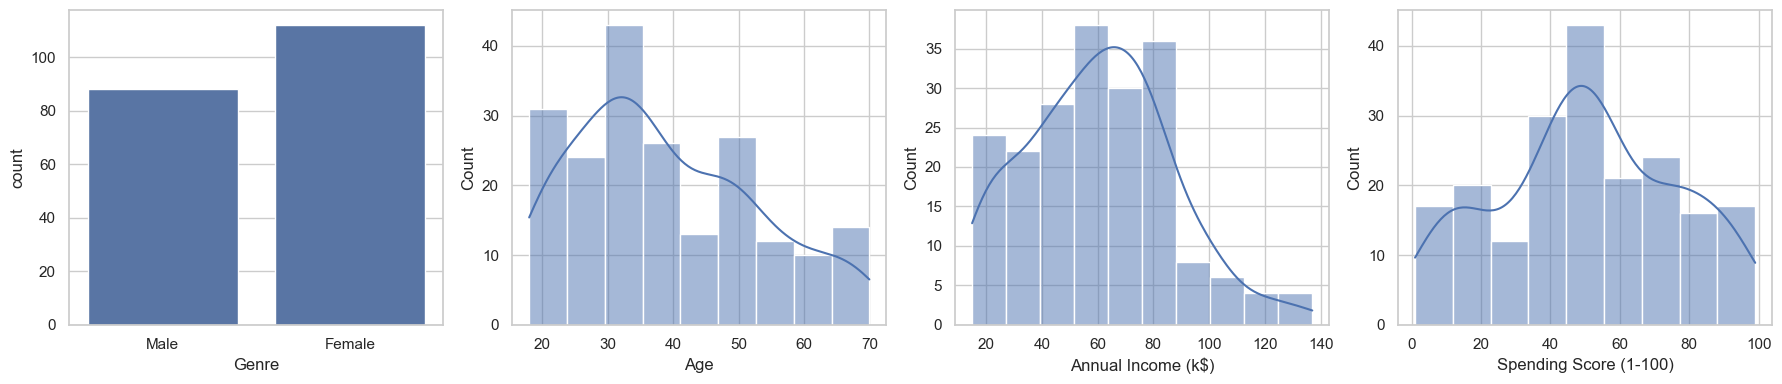

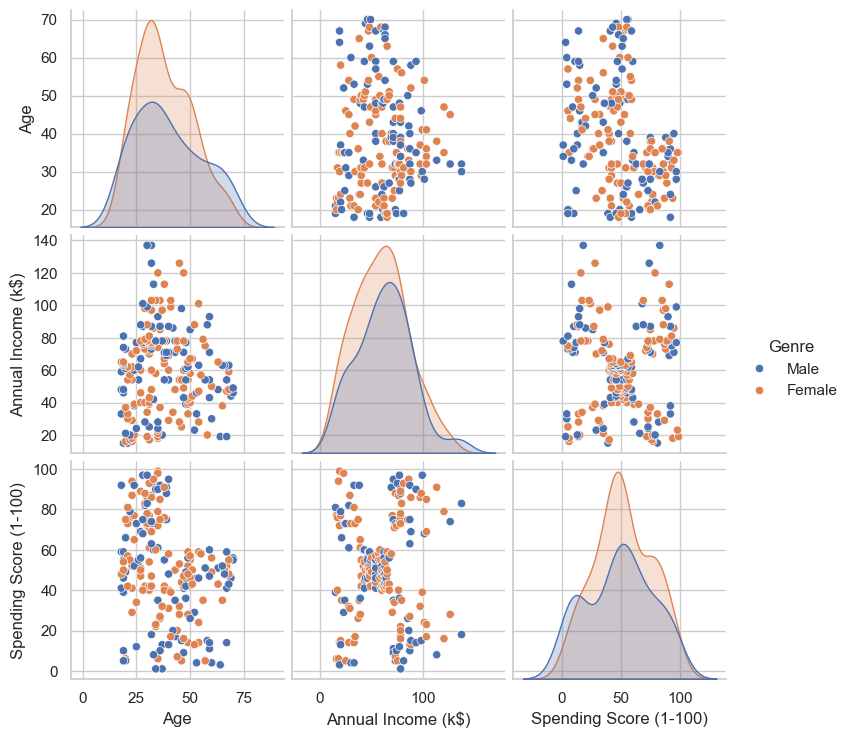

In [4]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
sns.countplot(x='Genre', data=df, ax=ax[0])
for i, c in enumerate(['Age', 'Annual Income (k$)', 'Spending Score (1-100)'], 1):
    sns.histplot(df[c], kde=True, ax=ax[i])
plt.tight_layout(); plt.savefig('results/clustering_eda.png', dpi=120); plt.show()
sns.pairplot(df.drop(columns='CustomerID'), hue='Genre'); plt.show()

## 2. Pre-processing

In [5]:
features = ['Annual Income (k$)', 'Spending Score (1-100)']
X = StandardScaler().fit_transform(df[features])
X[:5]

array([[-1.73899919, -0.43480148],
       [-1.73899919,  1.19570407],
       [-1.70082976, -1.71591298],
       [-1.70082976,  1.04041783],
       [-1.66266033, -0.39597992]])

## 3. Choosing the number of clusters (Elbow + Silhouette + Dendrogram)

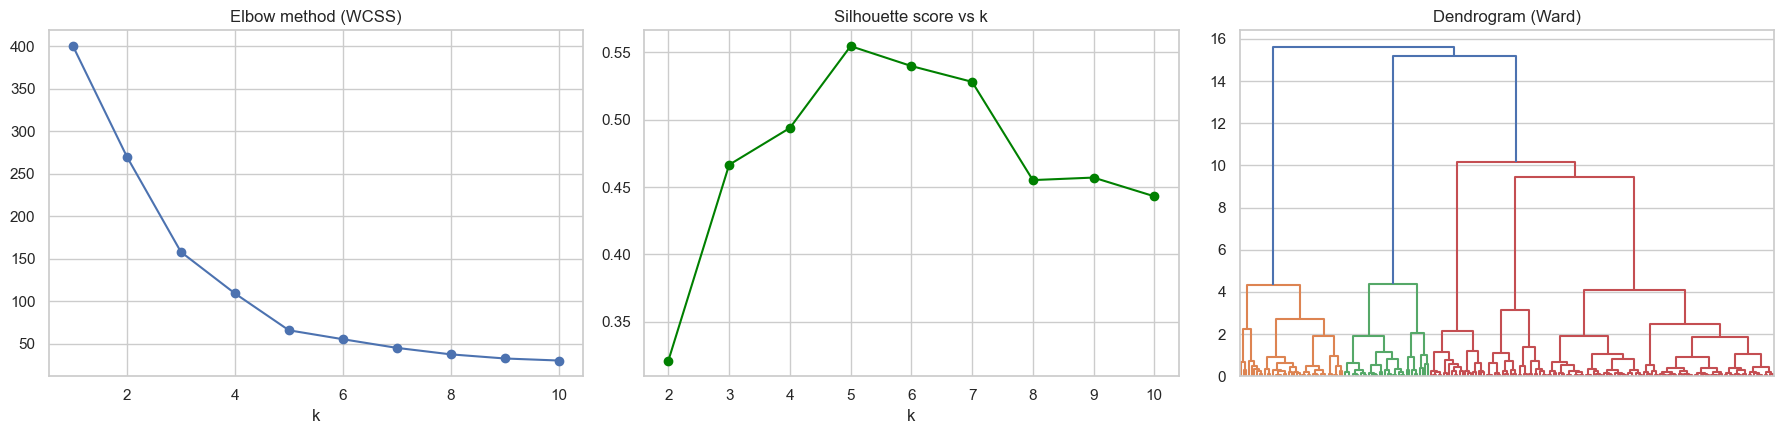

Optimal number of clusters k = 5


In [6]:
ks = range(2, 11)
wcss = [KMeans(n_clusters=k, n_init=10, random_state=RS).fit(X).inertia_ for k in range(1, 11)]
sil = [silhouette_score(X, KMeans(n_clusters=k, n_init=10, random_state=RS).fit_predict(X)) for k in ks]
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].plot(range(1, 11), wcss, 'o-'); ax[0].set_title('Elbow method (WCSS)'); ax[0].set_xlabel('k')
ax[1].plot(list(ks), sil, 'o-', color='green'); ax[1].set_title('Silhouette score vs k'); ax[1].set_xlabel('k')
dendrogram(linkage(X, method='ward'), ax=ax[2], no_labels=True); ax[2].set_title('Dendrogram (Ward)')
plt.tight_layout(); plt.savefig('results/clustering_choose_k.png', dpi=120); plt.show()
K = list(ks)[int(np.argmax(sil))]
print('Optimal number of clusters k =', K)

## 4. Tune DBSCAN (density-based, does not take k)

In [7]:
best_db = None
for eps in np.arange(0.20, 0.61, 0.05):
    for ms in range(3, 11):
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        mask = lab != -1
        n = len(set(lab[mask]))
        if n < 2 or mask.mean() < 0.85:          # need >=2 clusters and <=15% noise
            continue
        s = silhouette_score(X[mask], lab[mask])
        if best_db is None or s > best_db[0]:
            best_db = (s, round(eps, 2), ms, n, 1 - mask.mean())
print('Best DBSCAN: silhouette=%.4f eps=%.2f min_samples=%d clusters=%d noise=%.1f%%' % (*best_db[:4], best_db[4] * 100))

Best DBSCAN: silhouette=0.5736 eps=0.45 min_samples=10 clusters=5 noise=14.5%


## 5. Fit all clustering algorithms

In [8]:
bw = estimate_bandwidth(X, quantile=0.15, random_state=RS)
models = {
    'K-Means':                       KMeans(n_clusters=K, n_init=10, random_state=RS),
    'Agglomerative (Ward)':          AgglomerativeClustering(n_clusters=K, linkage='ward'),
    'Gaussian Mixture (GMM)':        GaussianMixture(n_components=K, n_init=5, random_state=RS),
    'Spectral Clustering':           SpectralClustering(n_clusters=K, affinity='nearest_neighbors', n_neighbors=10, random_state=RS),
    'BIRCH':                         Birch(n_clusters=K, threshold=0.3),
    'Mean Shift':                    MeanShift(bandwidth=bw),
    'DBSCAN':                        DBSCAN(eps=best_db[1], min_samples=best_db[2]),
}
rows, labels = [], {}
for name, m in models.items():
    lab = m.fit_predict(X)
    labels[name] = lab
    mask = lab != -1                     # DBSCAN noise points are excluded from the scores
    rows.append({'Algorithm': name,
                 'Clusters': len(set(lab[mask])),
                 'Noise points': int((~mask).sum()),
                 'Silhouette': silhouette_score(X[mask], lab[mask]),
                 'Davies-Bouldin': davies_bouldin_score(X[mask], lab[mask]),
                 'Calinski-Harabasz': calinski_harabasz_score(X[mask], lab[mask])})
results = pd.DataFrame(rows).sort_values('Silhouette', ascending=False).reset_index(drop=True)
results.index += 1
results.round(4)

,Algorithm,Clusters,Noise points,Silhouette,Davies-Bouldin,Calinski-Harabasz
1,DBSCAN,5,29,0.5736,0.4830,245.1439
2,K-Means,5,0,0.5547,0.5722,248.6493
3,Agglomerative (Ward),5,0,0.5538,0.5779,244.4103
4,Gaussian Mixture (GMM),5,0,0.5537,0.5760,244.9402
5,Mean Shift,5,0,0.5495,0.5698,246.5780
6,Spectral Clustering,5,0,0.5447,0.5860,243.7973
7,BIRCH,5,0,0.4781,0.6477,144.0135


In [9]:
results.round(4).to_csv('results/clustering_results.csv', index_label='Rank')
# DBSCAN's silhouette is computed only on the points it did NOT mark as noise, so it is not a like-for-like
# comparison. The best algorithm is therefore chosen among methods that assign every customer to a cluster.
full = results[results['Noise points'] == 0]
best = full.iloc[0]['Algorithm']
print(f"BEST CLUSTERING ALGORITHM: {best}  ->  Silhouette = {full.iloc[0]['Silhouette']:.4f}, "
      f"Davies-Bouldin = {full.iloc[0]['Davies-Bouldin']:.4f}, Calinski-Harabasz = {full.iloc[0]['Calinski-Harabasz']:.2f}")
n_noise = results.set_index('Algorithm').loc['DBSCAN', 'Noise points']
print(f"Note: DBSCAN scores highest only because {n_noise} of 200 customers ({n_noise/2:.1f}%) were discarded as noise.")

BEST CLUSTERING ALGORITHM: K-Means  ->  Silhouette = 0.5547, Davies-Bouldin = 0.5722, Calinski-Harabasz = 248.65
Note: DBSCAN scores highest only because 29 of 200 customers (14.5%) were discarded as noise.


## 6. Visualise the clusters

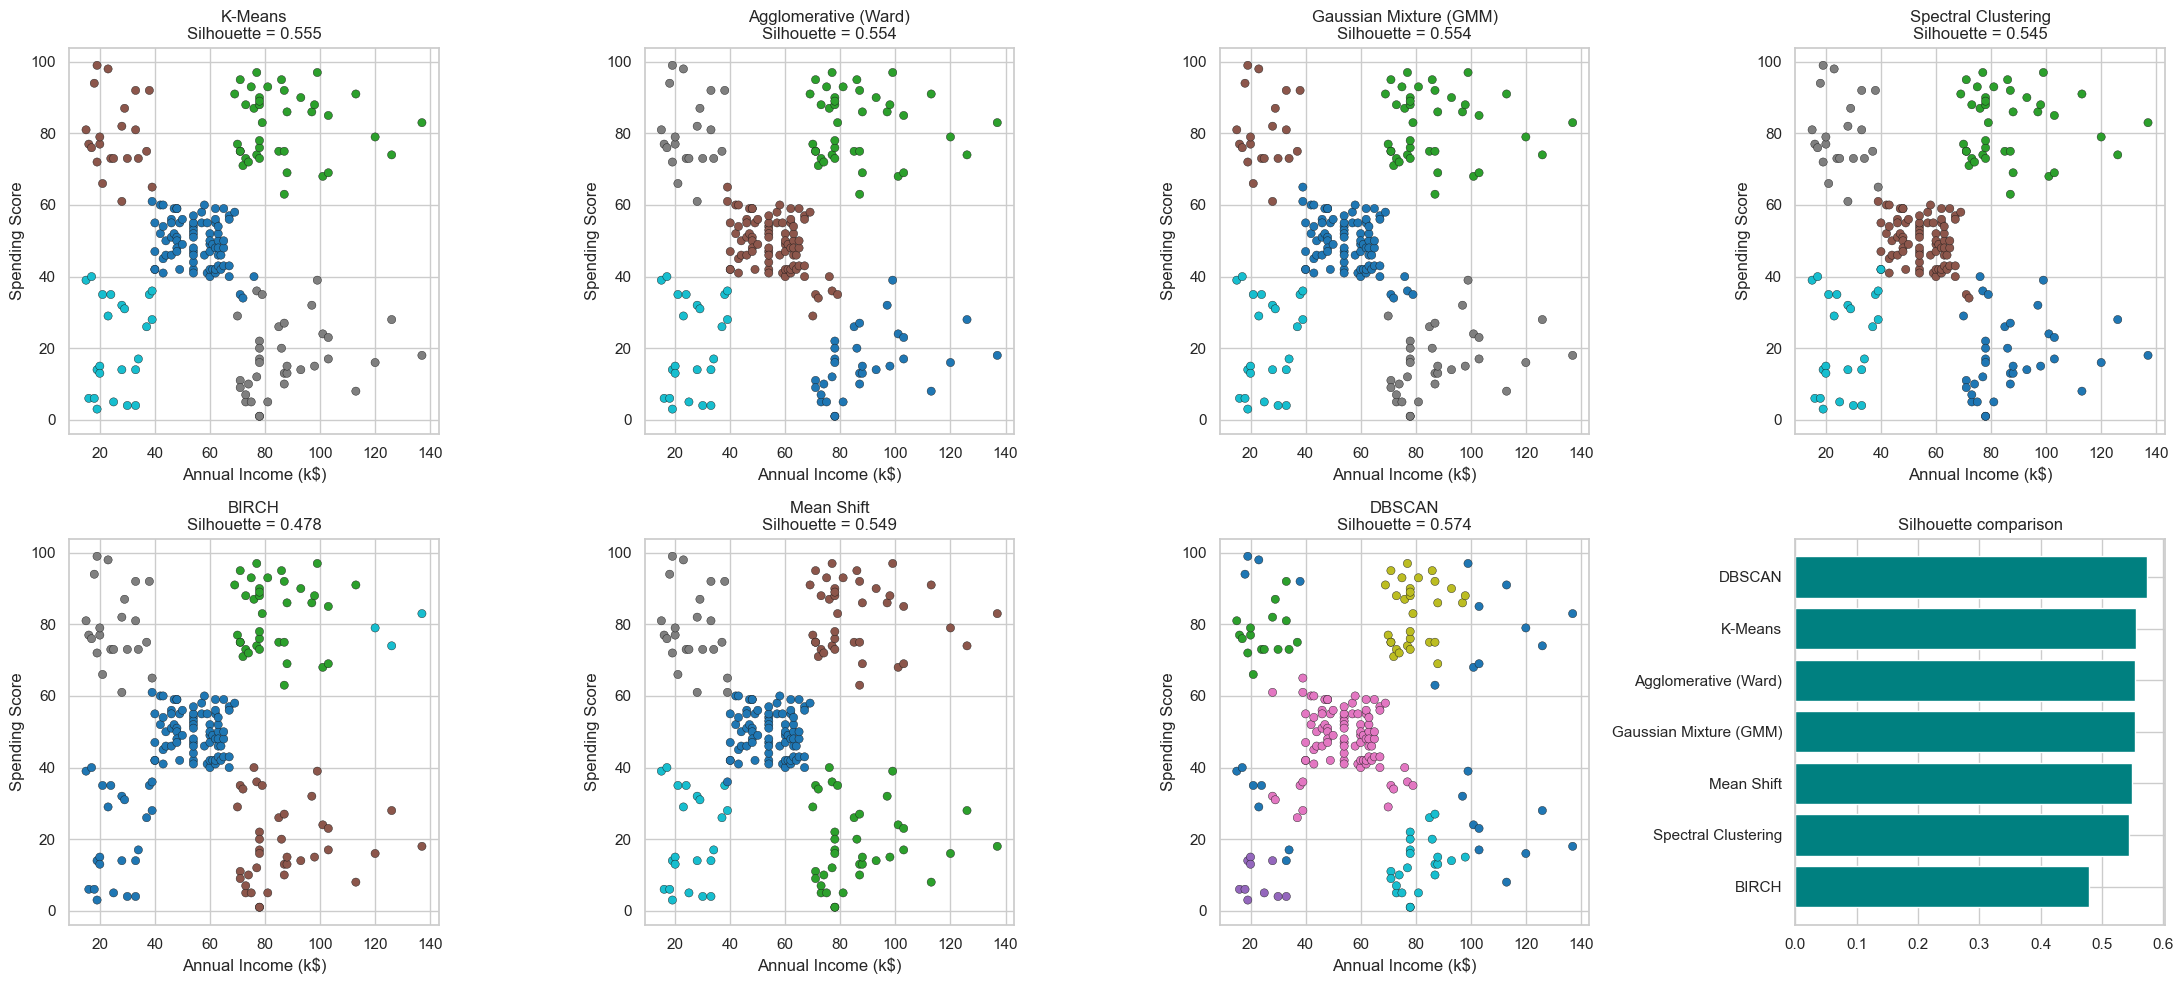

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(22, 10)); axes = axes.ravel()
for ax, (name, lab) in zip(axes, labels.items()):
    ax.scatter(df[features[0]], df[features[1]], c=lab, cmap='tab10', s=35, edgecolor='k', linewidth=0.3)
    s = results.set_index('Algorithm').loc[name, 'Silhouette']
    ax.set_title(f'{name}\nSilhouette = {s:.3f}'); ax.set_xlabel('Annual Income (k$)'); ax.set_ylabel('Spending Score')
ax = axes[-1]
ax.barh(results['Algorithm'], results['Silhouette'], color='teal'); ax.invert_yaxis(); ax.set_title('Silhouette comparison')
plt.tight_layout(); plt.savefig('results/clustering_comparison.png', dpi=120); plt.show()

## 7. Interpret the segments (best model)

In [11]:
df['Cluster'] = labels[best]
profile = df.groupby('Cluster')[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].mean().round(1)
profile['Customers'] = df['Cluster'].value_counts().sort_index()
def name_segment(r):
    inc = 'High income' if r['Annual Income (k$)'] > 70 else ('Low income' if r['Annual Income (k$)'] < 40 else 'Mid income')
    sp = 'high spend' if r['Spending Score (1-100)'] > 60 else ('low spend' if r['Spending Score (1-100)'] < 40 else 'average spend')
    return f'{inc}, {sp}'
profile['Segment'] = profile.apply(name_segment, axis=1)
profile

,Age,Annual Income (k$),Spending Score (1-100),Customers,Segment
Cluster,,,,,
0,42.7,55.3,49.5,81,"Mid income, average spend"
1,32.7,86.5,82.1,39,"High income, high spend"
2,25.3,25.7,79.4,22,"Low income, high spend"
3,41.1,88.2,17.1,35,"High income, low spend"
4,45.2,26.3,20.9,23,"Low income, low spend"


## 8. Conclusion
With k = 5 the customers split into five clear segments (low/high income × low/high spend, plus an average centre group).

- **K-Means is the best algorithm** for this dataset: highest Silhouette (0.555) and Calinski-Harabasz (248.6) among all methods that assign every customer to a segment.
- Agglomerative (Ward), GMM and Mean Shift find almost identical groups (Silhouette ≈ 0.55).
- DBSCAN shows the highest raw Silhouette (0.574), but only after discarding 29 customers (14.5 %) as noise. Those customers can't be targeted, so DBSCAN is not chosen.
- BIRCH is the weakest (0.478), because its CF-tree sub-clustering merges two of the natural groups.

**Business use:** the *High income, high spend* segment is the target for premium offers; *High income, low spend* is the biggest growth opportunity.